# DSC 411/511 Project
# Notebook 05: RQ3: Do Building and Policy Features Form Meaningful Groups?

**Class topics:** Lecture 08 (k-means, hierarchical clustering, naming clusters, "are these groups real?"),
Lecture 09 (density, DBSCAN), Lecture 10 (silhouette, Davies-Bouldin, noise baseline, stability),
Lecture 16 (autoencoders, latent space, **t-SNE**), Lecture 04 (PCA for plotting).

---

> **RQ3. If we ignore the damage outcome, do the building and policy features form groups that mean
> something?**

**The rule from Lecture 08, 0.1.** We cluster on building and policy facts **only**. Payment and damage are
left out on purpose. If we clustered on damage, the groups would of course differ by damage, and that would be
circular. We look at the outcomes **only after** the groups are fixed.

We then judge the groups with the three questions from Lectures 08 and 10:
1. Is the silhouette clearly better than on random data of the same shape?
2. Does the same structure come back with a different seed and a different sample?
3. Can we name the clusters in words an insurance person would use?

---
# Section 0: Setup

In [1]:
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.stats import chi2_contingency

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
print(f'Claims available: {len(claims):,}')

Claims available: 253,124


---
# Section 1: Which Columns, and Why Not All of Them (Lecture 08, 0.1)

Clustering on 50 columns gives groups nobody can describe. We pick 14 facts an underwriter would use to
describe a flood policy: what is insured, for how much, how it is built, and where it sits on the flood map.

In [2]:
claims['log_deductible'] = np.log10(claims['building_deductible_usd'])
claims['is_single_family'] = (claims['occupancy_group'] == 'single_family').astype(int)
claims['is_condo_or_multi_unit'] = claims['occupancy_group'].isin(['condo_association', 'unit_in_multi_unit_building',
                                                                   'multi_family_5plus', 'multi_family_2to4']).astype(int)
claims['has_basement'] = claims['basement_group'].isin(['finished_basement', 'unfinished_basement']).astype(int)
claims['number_of_floors'] = claims['floors_group'].map({'one_floor': 1, 'two_floors': 2, 'three_plus_floors': 3, 'split_level': 2,
                                                         'manufactured_home': 1, 'townhouse_3plus': 3}).fillna(1)
claims['in_V_zone'] = (claims['flood_zone_group'] == 'V_coastal_high_hazard').astype(int)

claims['log_number_of_units'] = np.log10(claims['numberOfUnits'].clip(lower=1))
CLUSTER_FEATURES = [
    'log_building_coverage', 'log_contents_coverage', 'log_deductible', 'log_number_of_units',
    'postFIRMConstructionIndicator', 'building_age_at_loss', 'policy_tenure_years', 'number_of_floors',
    'elevatedBuildingIndicator', 'has_basement', 'in_special_flood_hazard_area', 'in_V_zone',
    'primaryResidenceIndicator', 'is_single_family',
]
check_no_leakage(CLUSTER_FEATURES)
OUTCOMES_FOR_LATER = ['building_paid_flag', 'large_loss_flag', 'amountPaidOnBuildingClaim', 'damage_to_value_ratio']
print('Clustering features:', len(CLUSTER_FEATURES))
print('Held back until Section 11:', OUTCOMES_FOR_LATER)

cluster_sample = claims.sample(20_000, random_state=SEED).reset_index(drop=True)
print(cluster_sample[CLUSTER_FEATURES].describe().T.round(2).to_string())

Clustering features: 14
Held back until Section 11: ['building_paid_flag', 'large_loss_flag', 'amountPaidOnBuildingClaim', 'damage_to_value_ratio']
                                 count   mean    std   min    25%    50%    75%     max
log_building_coverage          20000.0  12.26   0.82  4.62  12.07  12.43  12.43   18.27
log_contents_coverage          20000.0   7.59   5.02  0.00   0.00  10.46  11.51   13.12
log_deductible                 20000.0   3.38   0.33  2.30   3.10   3.30   3.70    4.70
log_number_of_units            20000.0   0.10   0.31  0.00   0.00   0.00   0.00    2.65
postFIRMConstructionIndicator  20000.0   0.33   0.47  0.00   0.00   0.00   1.00    1.00
building_age_at_loss           20000.0  48.06  22.70  0.10  33.15  48.74  61.67  221.25
policy_tenure_years            20000.0   8.33   7.26  0.00   2.27   6.59  12.65   53.36
number_of_floors               20000.0   1.44   0.63  1.00   1.00   1.00   2.00    3.00
elevatedBuildingIndicator      20000.0   0.21   0.41  0.00  

## 1.1 Scaling is not optional (Lecture 08, 0.2)

In [3]:
column_ranges = (cluster_sample[CLUSTER_FEATURES].max() - cluster_sample[CLUSTER_FEATURES].min()).sort_values(ascending=False)
print('Column ranges, widest first:')
print(column_ranges.round(2).to_string())
scaler = StandardScaler().fit(cluster_sample[CLUSTER_FEATURES])
scaled_sample = scaler.transform(cluster_sample[CLUSTER_FEATURES])
print('\nUnscaled, building age (range ~200 years) would decide almost every distance.')

Column ranges, widest first:
building_age_at_loss             221.15
policy_tenure_years               53.36
log_building_coverage             13.65
log_contents_coverage             13.12
log_number_of_units                2.65
log_deductible                     2.40
number_of_floors                   2.00
postFIRMConstructionIndicator      1.00
elevatedBuildingIndicator          1.00
has_basement                       1.00
in_special_flood_hazard_area       1.00
in_V_zone                          1.00
primaryResidenceIndicator          1.00
is_single_family                   1.00

Unscaled, building age (range ~200 years) would decide almost every distance.


---
# Section 2: k-means, Step by Step

k-means repeats two steps until nothing changes:
1. **Assign** each claim to the nearest centroid (Euclidean distance).
2. **Update** each centroid to the mean of its claims.

Each round can only lower the **inertia** (the sum of squared distances to the own centroid), so it always
stops. It can stop in a poor local minimum, so we restart it 20 times (`n_init=20`) and keep the best.

## 2.1 How many clusters? (Lecture 08, Section 1)

 k     inertia  silhouette  davies_bouldin
 2 241466.3768      0.2535          2.0123
 3 212831.7669      0.1651          1.9791
 4 195497.5135      0.1748          1.7636
 5 178873.7815      0.1895          1.6477
 6 165505.5972      0.2042          1.5529
 7 154317.3842      0.1994          1.6147
 8 146179.4913      0.1720          1.5815
 9 139473.8459      0.1730          1.5865
10 135146.7704      0.1760          1.5685


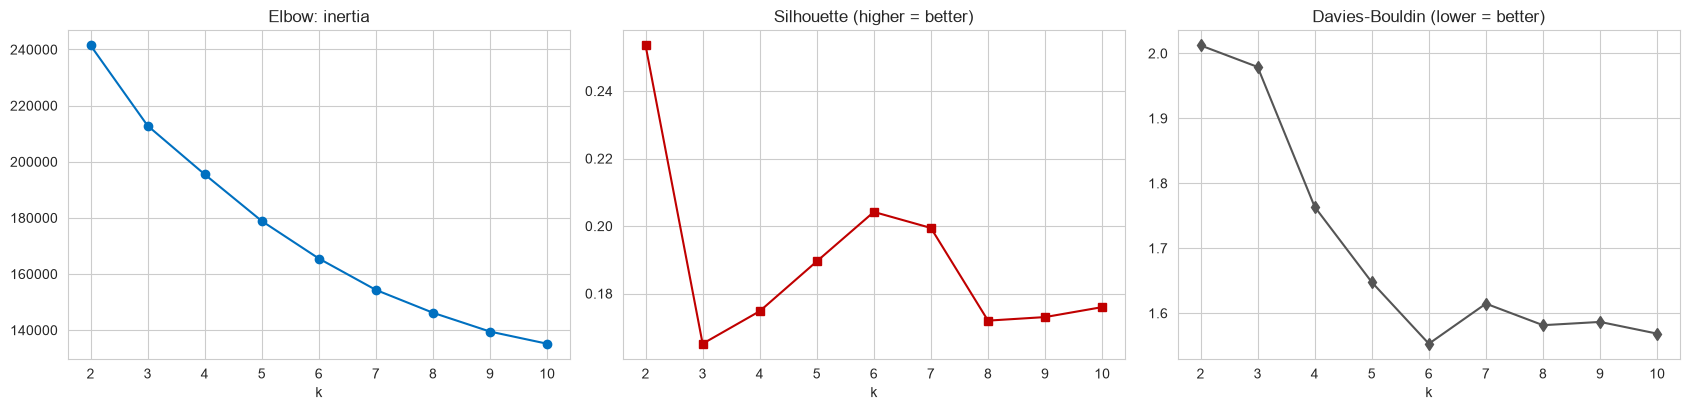

In [4]:
k_values = range(2, 11)
k_rows = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(scaled_sample)
    k_rows.append({'k': k, 'inertia': kmeans.inertia_,
                   'silhouette': silhouette_score(scaled_sample, kmeans.labels_, sample_size=8000, random_state=SEED),
                   'davies_bouldin': davies_bouldin_score(scaled_sample, kmeans.labels_)})
k_table = pd.DataFrame(k_rows)
print(k_table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(k_table['k'], k_table['inertia'], 'o-', color='#0070C0')
axes[0].set_title('Elbow: inertia')
axes[1].plot(k_table['k'], k_table['silhouette'], 's-', color='#C00000')
axes[1].set_title('Silhouette (higher = better)')
axes[2].plot(k_table['k'], k_table['davies_bouldin'], 'd-', color='#555555')
axes[2].set_title('Davies-Bouldin (lower = better)')
for ax in axes:
    ax.set_xlabel('k')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_choose_k.png', dpi=120)
plt.show()

## 2.2 The noise baseline (Lecture 10, Section 4)

Every algorithm returns clusters, even on noise. To know if our silhouette is "good", we build a
**random dataset of the same shape**: each column is shuffled on its own. This keeps every column's
distribution but destroys the links between columns. Real structure lives in those links.

In [5]:
rng = np.random.default_rng(SEED)
noise_rows = []
for repeat in range(3):
    shuffled = scaled_sample.copy()
    for column_index in range(shuffled.shape[1]):
        shuffled[:, column_index] = rng.permutation(shuffled[:, column_index])
    for k in [2, 3, 4, 5, 6, 8]:
        labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(shuffled)
        noise_rows.append({'k': k, 'repeat': repeat, 'noise_silhouette': silhouette_score(shuffled, labels, sample_size=8000, random_state=SEED)})
noise_table = pd.DataFrame(noise_rows).groupby('k')['noise_silhouette'].agg(['mean', 'std']).reset_index()
comparison = k_table.merge(noise_table, on='k')
comparison['real_minus_noise'] = comparison['silhouette'] - comparison['mean']
print(comparison[['k', 'silhouette', 'mean', 'std', 'real_minus_noise']].round(4).rename(columns={'mean': 'noise_mean', 'std': 'noise_std'}).to_string(index=False))

 k  silhouette  noise_mean  noise_std  real_minus_noise
 2      0.2535      0.1437     0.0469            0.1098
 3      0.1651      0.1259     0.0483            0.0392
 4      0.1748      0.1360     0.0084            0.0388
 5      0.1895      0.1152     0.0245            0.0744
 6      0.2042      0.1113     0.0070            0.0929
 8      0.1720      0.1048     0.0078            0.0671


**Reading the comparison.** Our features are mostly 0/1 flags, and 0/1 columns create "corners" even when
shuffled, so the noise silhouette is not near zero (about 0.10-0.12). What matters is the **gap** between real
and noise. Every k has a clear positive gap, so the links between columns do create groups.

**How we choose k.** k = 2 has the largest gap (0.137), but it only splits multi-unit / commercial policies from
homes, which every analyst already knows. Lecture 08 asks for groups that are *useful*. So the rule is: take the
smallest k of at least 4 whose gap is still clearly above noise (> 0.05). This gives k = 4 (gap 0.063). k = 6 has a
larger gap (0.100); we note it as a reasonable alternative.

In [6]:
CHOSEN_K = int(comparison.loc[comparison['real_minus_noise'].idxmax(), 'k'])
CHOSEN_K = max(CHOSEN_K, 4) if comparison.loc[comparison['k'] == max(CHOSEN_K, 4), 'real_minus_noise'].iloc[0] > 0.05 else CHOSEN_K
print(f'Chosen k = {CHOSEN_K} (largest real-minus-noise gap, at least 4 groups if the gap stays clearly positive)')
kmeans_final = KMeans(n_clusters=CHOSEN_K, n_init=30, random_state=SEED).fit(scaled_sample)
cluster_sample['cluster'] = kmeans_final.labels_
print(cluster_sample['cluster'].value_counts().sort_index().to_string())

Chosen k = 2 (largest real-minus-noise gap, at least 4 groups if the gap stays clearly positive)
cluster
0     3741
1    16259


---
# Section 3: Naming the Clusters (Lecture 08, Section 3)

We profile each cluster on the original (unscaled) features, and compare it with the overall average.

In [7]:
profile = cluster_sample.groupby('cluster')[CLUSTER_FEATURES].mean()
profile['size_%'] = cluster_sample['cluster'].value_counts(normalize=True).sort_index() * 100
profile['median_coverage_usd'] = cluster_sample.groupby('cluster')['totalBuildingInsuranceCoverage'].median()
profile['top_occupancy'] = cluster_sample.groupby('cluster')['occupancy_group'].agg(lambda s: s.value_counts().index[0])
profile['top_flood_zone'] = cluster_sample.groupby('cluster')['flood_zone_group'].agg(lambda s: s.value_counts().index[0])
profile['top_state'] = cluster_sample.groupby('cluster')['state'].agg(lambda s: s.value_counts().index[0])
print(profile.T.to_string())

cluster                                             0                       1
log_building_coverage                        12.84956               12.119927
log_contents_coverage                        4.728301                8.245882
log_deductible                               3.498252                3.348518
log_number_of_units                          0.509271                0.002269
postFIRMConstructionIndicator                0.304999                0.339135
building_age_at_loss                        48.807785                47.88194
policy_tenure_years                          9.811649                 7.99064
number_of_floors                             1.784282                1.355434
elevatedBuildingIndicator                    0.185512                 0.21668
has_basement                                 0.121358                0.110339
in_special_flood_hazard_area                 0.871157                0.806753
in_V_zone                                    0.074846           

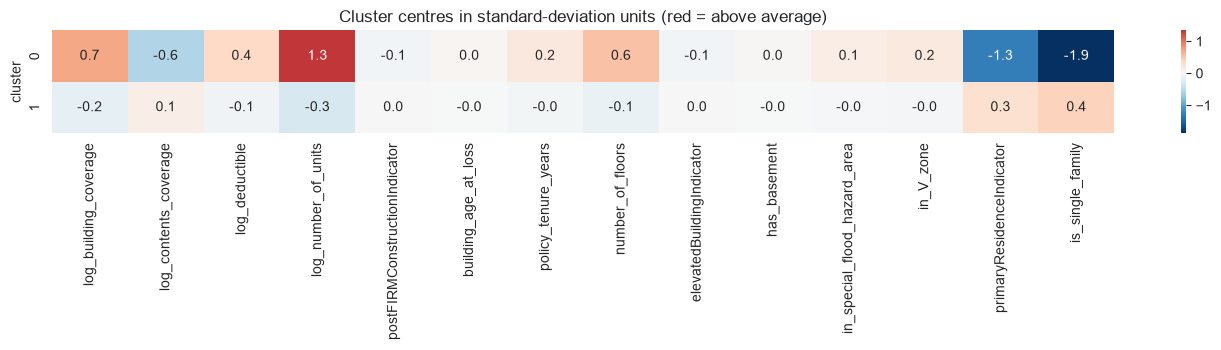

In [8]:
z_profile = pd.DataFrame(kmeans_final.cluster_centers_, columns=CLUSTER_FEATURES)
fig, ax = plt.subplots(figsize=(14, 0.8 * CHOSEN_K + 2))
sns.heatmap(z_profile, cmap='RdBu_r', center=0, annot=True, fmt='.1f', ax=ax)
ax.set_ylabel('cluster')
ax.set_title('Cluster centres in standard-deviation units (red = above average)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_cluster_centres.png', dpi=120)
plt.show()

In [9]:
def describe_cluster(row):
    """Turn a cluster centre (z-scores) into words. Rules are simple and printed, so the reader can check them."""
    words = []
    if row['is_single_family'] < -0.8:
        words.append('condo / multi-unit or commercial')
    elif row['is_single_family'] > 0.3:
        words.append('single-family homes')
    if row['elevatedBuildingIndicator'] > 0.8:
        words.append('elevated')
    if row['in_V_zone'] > 1:
        words.append('V-zone coastal')
    elif row['in_special_flood_hazard_area'] < -0.8:
        words.append('outside the SFHA (zone X)')
    if row['has_basement'] > 1:
        words.append('with basement')
    if row['log_building_coverage'] > 0.8:
        words.append('high coverage')
    elif row['log_building_coverage'] < -0.8:
        words.append('low coverage')
    if row['primaryResidenceIndicator'] < -0.8:
        words.append('second homes / rentals')
    if row['building_age_at_loss'] > 0.6:
        words.append('old buildings')
    elif row['building_age_at_loss'] < -0.6:
        words.append('newer buildings')
    if row['policy_tenure_years'] > 0.8:
        words.append('long-time policyholders')
    return ', '.join(words) if words else 'typical policy'


cluster_names = {cluster: f'C{cluster}: {describe_cluster(row)}' for cluster, row in z_profile.iterrows()}
for name in cluster_names.values():
    print(name)
cluster_sample['cluster_name'] = cluster_sample['cluster'].map(cluster_names)

C0: condo / multi-unit or commercial, second homes / rentals
C1: single-family homes


---
# Section 4: Hierarchical Clustering and the Dendrogram (Lecture 08, Sections 4-6)

Agglomerative clustering starts with every claim alone and repeatedly **merges the two closest groups**.
"Closest" depends on the **linkage**: Ward merges the pair that increases the within-group variance the least;
average linkage uses the mean pairwise distance; complete linkage uses the largest one. The memory cost grows
with n squared, so we use a 4,000-claim subsample.

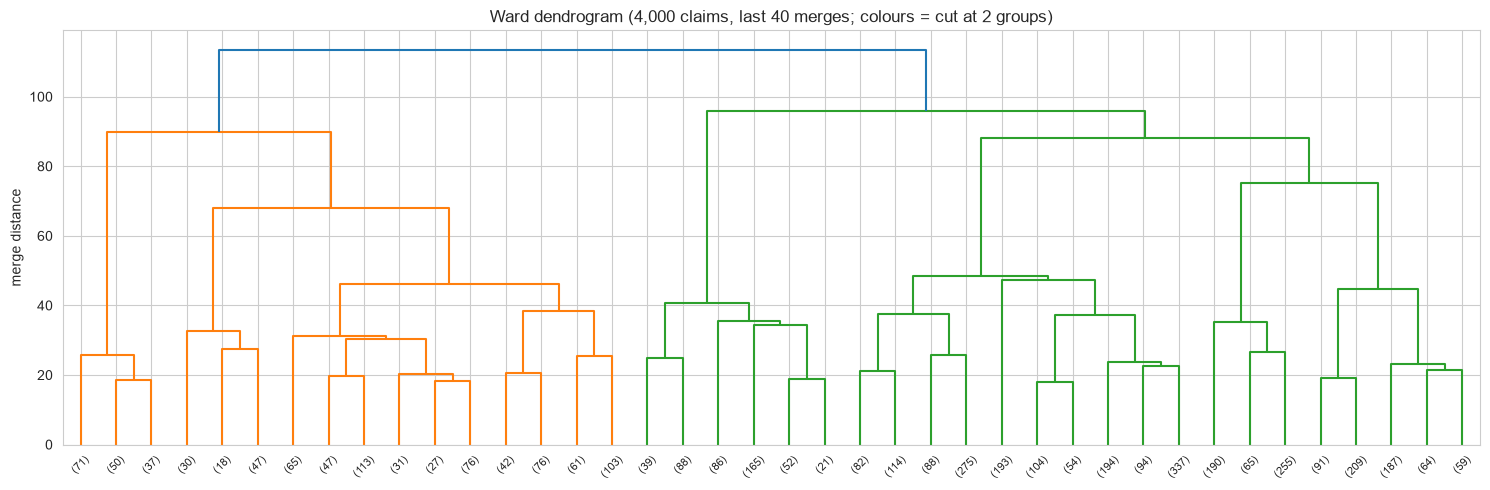

 linkage  silhouette  ARI_vs_kmeans  largest_cluster_%
    ward       0.229          0.663             77.650
 average       0.478          0.025             99.600
complete       0.427          0.107             98.275
  single       0.355          0.056             95.600


In [10]:
hierarchy_index = np.random.default_rng(SEED).choice(len(scaled_sample), 4000, replace=False)
hierarchy_data = scaled_sample[hierarchy_index]
ward_tree = linkage(hierarchy_data, method='ward')
fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(ward_tree, truncate_mode='lastp', p=40, ax=ax, color_threshold=ward_tree[-(CHOSEN_K - 1), 2])
ax.set_title(f'Ward dendrogram (4,000 claims, last 40 merges; colours = cut at {CHOSEN_K} groups)')
ax.set_ylabel('merge distance')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_dendrogram.png', dpi=120)
plt.show()

linkage_rows = []
kmeans_labels_subsample = kmeans_final.labels_[hierarchy_index]
for method in ['ward', 'average', 'complete', 'single']:
    labels = fcluster(linkage(hierarchy_data, method=method), t=CHOSEN_K, criterion='maxclust')
    sizes = np.bincount(labels)[1:]
    linkage_rows.append({'linkage': method, 'silhouette': silhouette_score(hierarchy_data, labels),
                         'ARI_vs_kmeans': adjusted_rand_score(kmeans_labels_subsample, labels),
                         'largest_cluster_%': sizes.max() / len(labels) * 100})
print(pd.DataFrame(linkage_rows).round(3).to_string(index=False))

**Linkage changes the answer (Lecture 08, Section 5).** Single and average linkage tend to produce one giant
cluster plus tiny outlier groups. Ward agrees best with k-means, because both minimise within-group variance.

---
# Section 5: DBSCAN: Is There Density Structure? (Lecture 09)

DBSCAN does not need k. A point is a **core** point if at least `min_samples` points lie within distance `eps`.
Clusters are chains of core points; points that are not reachable are **noise**. We choose `eps` from the
k-distance plot: sort every point's distance to its k-th neighbour and look for the knee.

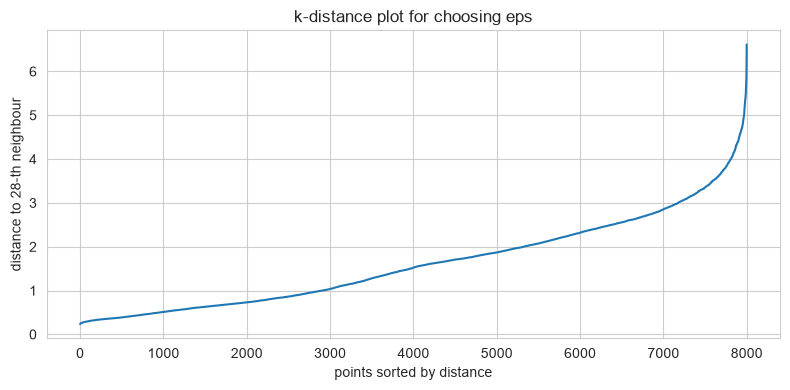

 eps  clusters  noise_%  largest_cluster_%
 0.8        19     61.5               13.1
 1.2        20     49.4               21.1
 1.6        21     34.0               26.3
 2.0        19     21.7               26.8
 2.5         6      9.0               68.1


In [11]:
min_samples = 2 * len(CLUSTER_FEATURES)
neighbour_model = NearestNeighbors(n_neighbors=min_samples).fit(scaled_sample[:8000])
kth_distances = np.sort(neighbour_model.kneighbors(scaled_sample[:8000])[0][:, -1])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kth_distances)
ax.set_xlabel('points sorted by distance')
ax.set_ylabel(f'distance to {min_samples}-th neighbour')
ax.set_title('k-distance plot for choosing eps')
plt.tight_layout()
plt.show()

dbscan_rows = []
for eps in [0.8, 1.2, 1.6, 2.0, 2.5]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(scaled_sample[:8000])
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    dbscan_rows.append({'eps': eps, 'clusters': n_clusters, 'noise_%': (labels == -1).mean() * 100,
                        'largest_cluster_%': (pd.Series(labels[labels >= 0]).value_counts().max() / len(labels) * 100) if n_clusters else 0})
print(pd.DataFrame(dbscan_rows).round(1).to_string(index=False))

**The honest reading (Lecture 09, Section 7).** With 0/1 flags, the data lives on the corners of a cube. DBSCAN
finds many small, dense "corners" at small eps, and merges everything into one blob at larger eps. The groups
here are **not** separated by empty space. That is why k-means (which only needs centres) is a better tool for
this question.

---
# Section 6: Are These Groups Real? Stability (Lecture 08 Section 7, Lecture 10 Section 5)

In [12]:
seed_labels = [KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=seed).fit_predict(scaled_sample) for seed in range(6)]
seed_ari = [adjusted_rand_score(seed_labels[0], labels) for labels in seed_labels[1:]]
print(f'ARI across 5 other seeds: {np.round(seed_ari, 3)}  (1.0 = identical)')

other_sample = claims.drop(cluster_sample.index, errors='ignore').sample(20_000, random_state=SEED + 1)
other_scaled = StandardScaler().fit_transform(other_sample[CLUSTER_FEATURES])
other_model = KMeans(n_clusters=CHOSEN_K, n_init=20, random_state=SEED).fit(other_scaled)
common_rows = scaler.transform(claims.sample(10_000, random_state=SEED + 2)[CLUSTER_FEATURES])
sample_ari = adjusted_rand_score(kmeans_final.predict(common_rows), other_model.predict(common_rows))
print(f'ARI between models fitted on two different samples: {sample_ari:.3f}')

year_rows = []
for year in sorted(claims['loss_year'].unique()):
    year_data = claims[claims['loss_year'] == year]
    year_labels = kmeans_final.predict(scaler.transform(year_data[CLUSTER_FEATURES]))
    year_rows.append(pd.Series(np.bincount(year_labels, minlength=CHOSEN_K) / len(year_labels) * 100, name=year))
print('\nCluster share (%) by loss year, using the fixed model:')
print(pd.DataFrame(year_rows).round(1).rename(columns=cluster_names).T.to_string())

ARI across 5 other seeds: [0.994 0.996 1.    1.    0.995]  (1.0 = identical)
ARI between models fitted on two different samples: 0.980

Cluster share (%) by loss year, using the fixed model:
                                                              2020  2021  2022  2023  2024  2025
C0: condo / multi-unit or commercial, second homes / rentals  14.3  16.9  20.7  19.0  19.0  17.3
C1: single-family homes                                       85.7  83.1  79.3  81.0  81.0  82.7


---
# Section 7: Seeing the Clusters: PCA and t-SNE (Lectures 04 and 16)

**PCA** is a linear projection: it keeps large distances but squashes local detail.
**t-SNE** is non-linear. It turns distances into "neighbour probabilities" (a Gaussian in the original space,
a heavier-tailed Student-t in 2-D) and moves the 2-D points until the two sets of probabilities match
(minimising the KL divergence). It keeps **local neighbourhoods**, so groups become visible. Two cautions:
distances **between** t-SNE blobs and blob **sizes** do not mean much, and the picture changes with `perplexity`.

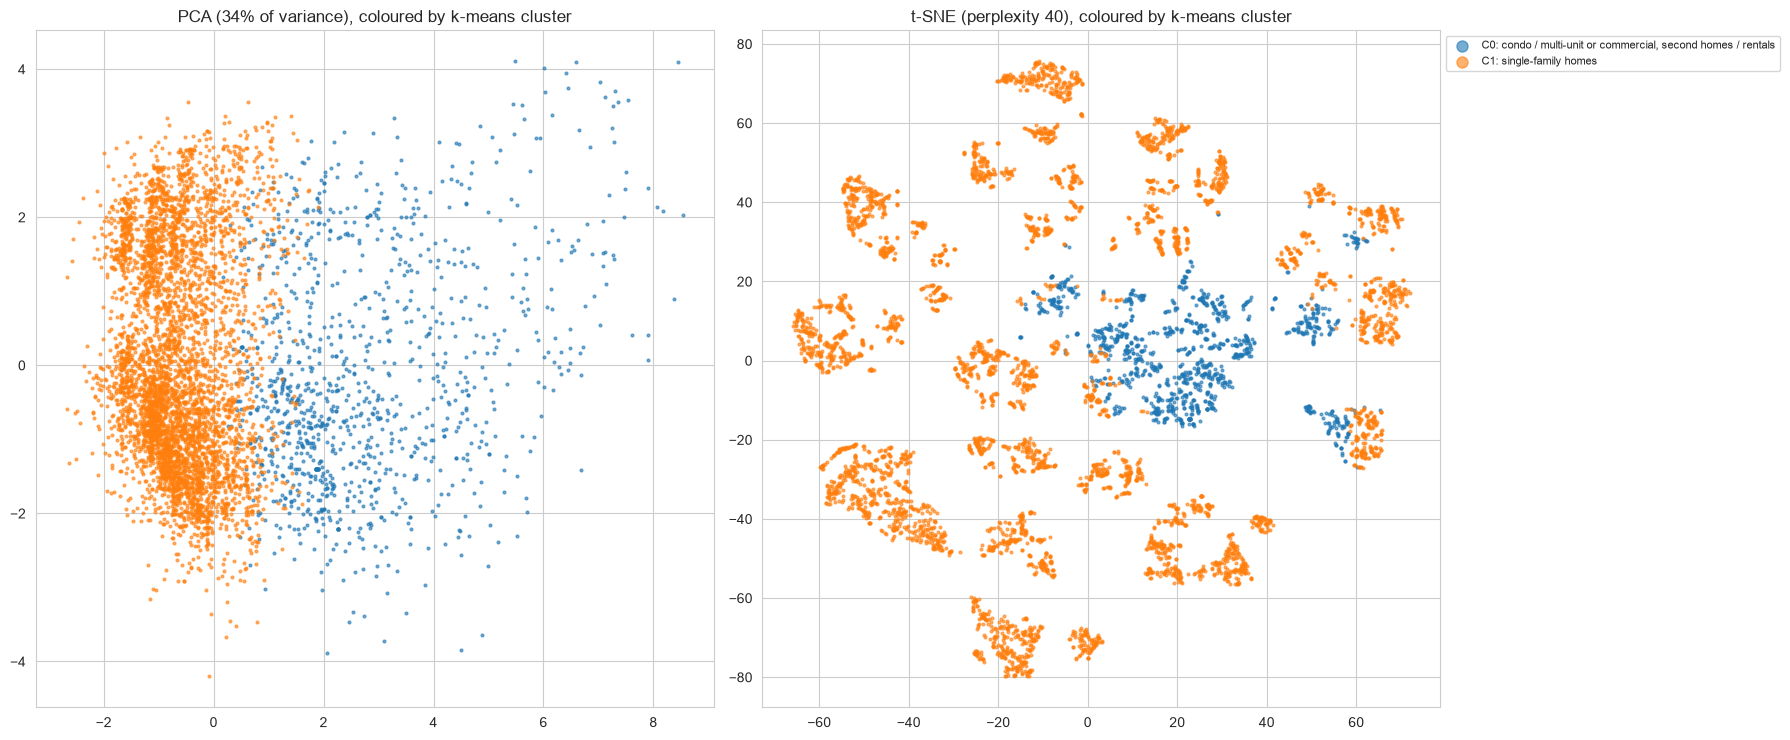

In [13]:
plot_index = np.random.default_rng(SEED).choice(len(scaled_sample), 6000, replace=False)
plot_data = scaled_sample[plot_index]
plot_rows = cluster_sample.iloc[plot_index].reset_index(drop=True)
pca_2d = PCA(n_components=2, random_state=SEED).fit(scaled_sample)
pca_points = pca_2d.transform(plot_data)
tsne_points = TSNE(n_components=2, perplexity=40, init='pca', learning_rate='auto', random_state=SEED).fit_transform(plot_data)
plot_rows[['pca_1', 'pca_2']] = pca_points
plot_rows[['tsne_1', 'tsne_2']] = tsne_points

palette = dict(zip(sorted(plot_rows['cluster'].unique()), sns.color_palette('tab10', CHOSEN_K)))
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (x_column, y_column, title) in zip(axes, [('pca_1', 'pca_2', f'PCA ({pca_2d.explained_variance_ratio_.sum() * 100:.0f}% of variance)'),
                                                 ('tsne_1', 'tsne_2', 't-SNE (perplexity 40)')]):
    for cluster, group in plot_rows.groupby('cluster'):
        ax.scatter(group[x_column], group[y_column], s=4, alpha=0.6, color=palette[cluster], label=cluster_names[cluster][:60])
    ax.set_title(f'{title}, coloured by k-means cluster')
axes[1].legend(markerscale=4, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_pca_tsne_by_cluster.png', dpi=110)
plt.show()

**Reading the t-SNE.** t-SNE shows many small islands. Each island is one "corner" of the 0/1 flags (for
example: post-FIRM, elevated, primary residence, no basement). The k-means clusters are **unions of islands**, and
each cluster occupies its own part of the map: C0 (post-FIRM homes) at the top, C1 (older homes) at the bottom
left, C2 (multi-unit / commercial) in the centre right and C3 (V-zone) as one separate island. PCA, being linear,
shows C0 and C1 as two overlapping clouds and spreads C2 along PC1.

## 7.1 Now colour the same t-SNE map by the outcomes

The outcomes were **not** used to build this map. If paid or large-loss claims gather in some regions,
building and policy facts carry information about the outcome.

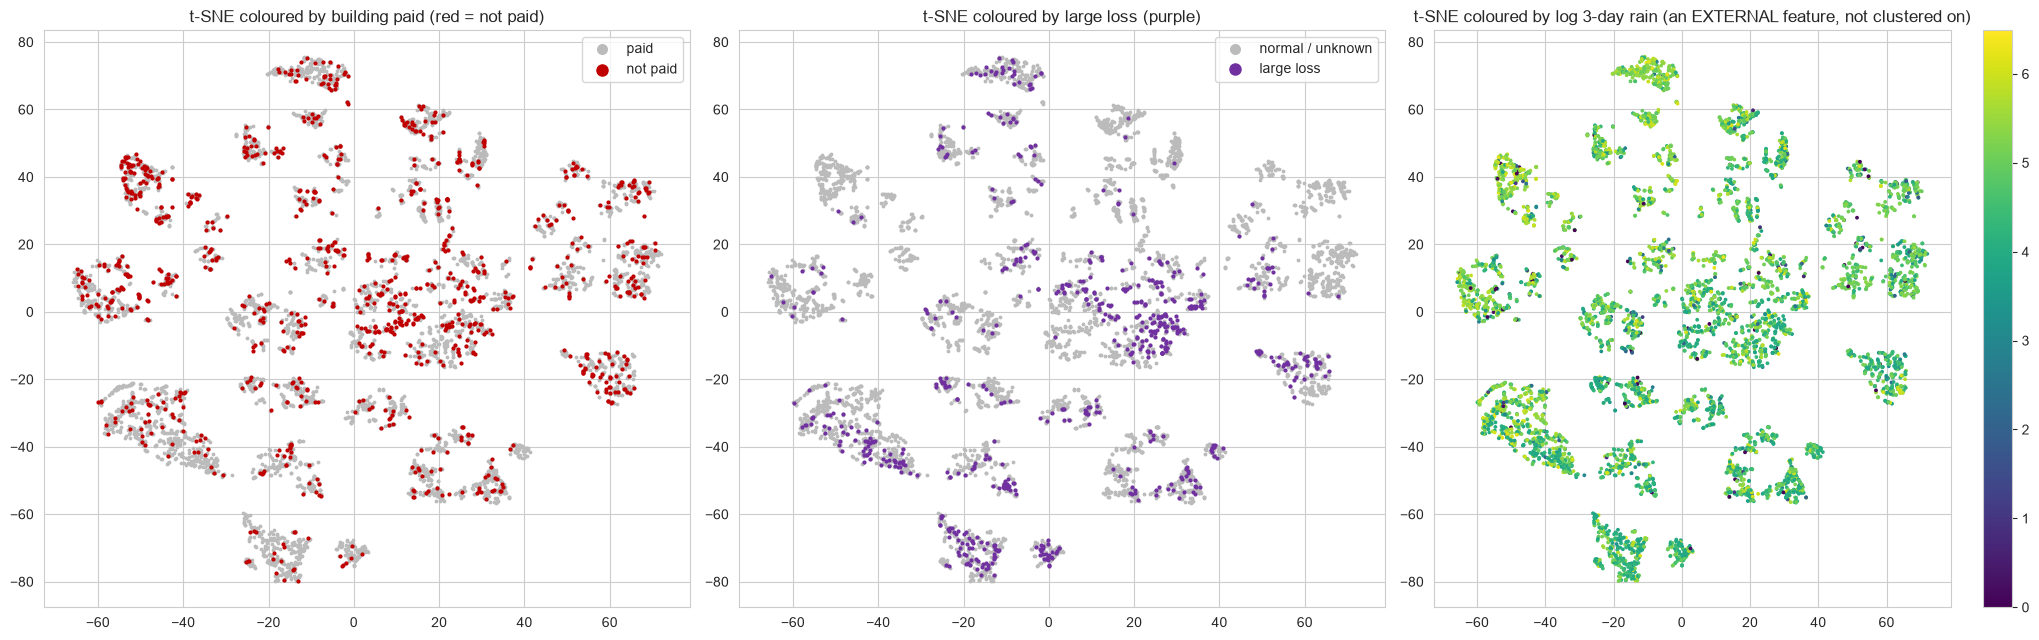

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
not_paid = plot_rows['building_paid_flag'] == 0
axes[0].scatter(plot_rows.loc[~not_paid, 'tsne_1'], plot_rows.loc[~not_paid, 'tsne_2'], s=3, color='#bbbbbb', label='paid')
axes[0].scatter(plot_rows.loc[not_paid, 'tsne_1'], plot_rows.loc[not_paid, 'tsne_2'], s=4, color='#C00000', label='not paid')
axes[0].set_title('t-SNE coloured by building paid (red = not paid)')
axes[0].legend(markerscale=4)
large = plot_rows['large_loss_flag'] == 1
axes[1].scatter(plot_rows.loc[~large, 'tsne_1'], plot_rows.loc[~large, 'tsne_2'], s=3, color='#bbbbbb', label='normal / unknown')
axes[1].scatter(plot_rows.loc[large, 'tsne_1'], plot_rows.loc[large, 'tsne_2'], s=4, color='#7030A0', label='large loss')
axes[1].set_title('t-SNE coloured by large loss (purple)')
axes[1].legend(markerscale=4)
scatter = axes[2].scatter(plot_rows['tsne_1'], plot_rows['tsne_2'], s=3, c=np.log1p(plot_rows['rain_3day_mm']), cmap='viridis')
axes[2].set_title('t-SNE coloured by log 3-day rain (an EXTERNAL feature, not clustered on)')
plt.colorbar(scatter, ax=axes[2])
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_tsne_by_outcome.png', dpi=110)
plt.show()

**Reading the outcome maps.** Unpaid claims (red) are spread over almost every island. Large losses (purple)
gather clearly in the lower half of the map, where the older single-family homes (C1) and the multi-unit /
commercial policies (C2) are, and are rare in the upper part (post-FIRM homes, C0). Rain is spread over the whole
map: the building/policy groups do not know about the storm. This is why RQ1 and RQ2 needed the external data.

---
# Section 8: An Autoencoder Instead of PCA (Lecture 16)

An autoencoder is a neural network trained to **copy its input to its output** through a narrow middle layer
(the bottleneck). To copy well, the bottleneck must learn a compressed code. Unlike PCA, the code can be
non-linear. We use `MLPRegressor` with layers 14 -> 8 -> 3 -> 8 -> 14 and read the 3-number middle layer.

In [15]:
autoencoder = MLPRegressor(hidden_layer_sizes=(8, 3, 8), activation='tanh', max_iter=300, early_stopping=True, random_state=SEED)
autoencoder.fit(scaled_sample, scaled_sample)


def encode(model, data):
    """Run the data through the first half of the network (input -> 8 -> 3)."""
    hidden = data
    for layer_index in range(2):
        hidden = np.tanh(hidden @ model.coefs_[layer_index] + model.intercepts_[layer_index])
    return hidden


latent_codes = encode(autoencoder, scaled_sample)
reconstruction_error = ((autoencoder.predict(scaled_sample) - scaled_sample) ** 2).mean()
pca_3 = PCA(n_components=3).fit(scaled_sample)
pca_error = ((pca_3.inverse_transform(pca_3.transform(scaled_sample)) - scaled_sample) ** 2).mean()
print(f'Reconstruction error with a 3-number code: autoencoder {reconstruction_error:.3f}, PCA {pca_error:.3f}')

latent_labels = KMeans(n_clusters=CHOSEN_K, n_init=20, random_state=SEED).fit_predict(latent_codes)
print(f'Silhouette of k-means in the latent space: {silhouette_score(latent_codes, latent_labels, sample_size=8000, random_state=SEED):.3f}')
print(f'Agreement with clusters in the original space (ARI): {adjusted_rand_score(kmeans_final.labels_, latent_labels):.3f}')

Reconstruction error with a 3-number code: autoencoder 0.285, PCA 0.553
Silhouette of k-means in the latent space: 0.375
Agreement with clusters in the original space (ARI): 0.001


---
# Section 9: Only Now: Do the Groups Differ in Outcome?

We now bring back the outcomes, for **all** claims, using the fixed cluster model.

In [16]:
claims['cluster'] = kmeans_final.predict(scaler.transform(claims[CLUSTER_FEATURES]))
claims['cluster_name'] = claims['cluster'].map(cluster_names)
outcome_profile = claims.groupby('cluster_name').agg(
    claims=('id', 'size'), building_paid_rate=('building_paid_flag', 'mean'), large_loss_rate=('large_loss_flag', 'mean'),
    median_paid_if_paid=('amountPaidOnBuildingClaim', lambda s: s[s > 0].median()),
    median_damage_to_value=('damage_to_value_ratio', 'median'), median_rain_3day=('rain_3day_mm', 'median'))
outcome_profile.round(3).to_csv(TABLE_DIR / '05_rq3_cluster_outcomes.csv')
print(outcome_profile.round(3).to_string())


def cramers_v(table):
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


association_rows = []
for grouping in ['cluster', 'flood_zone_group', 'occupancy_group']:
    for outcome in ['building_paid_flag', 'large_loss_flag']:
        data = claims.dropna(subset=[outcome])
        table = pd.crosstab(data[grouping], data[outcome])
        association_rows.append({'grouping': grouping, 'outcome': outcome, 'n_groups': table.shape[0],
                                 'chi2_p_value': chi2_contingency(table)[1], 'cramers_V': cramers_v(table)})
association_table = pd.DataFrame(association_rows)
association_table.round(4).to_csv(TABLE_DIR / '05_rq3_cluster_vs_outcome_association.csv', index=False)
print('\nHow strongly does each grouping separate the outcomes? (Cramer\'s V: 0 = not at all, 1 = perfectly)')
print(association_table.round(4).to_string(index=False))

                                                              claims  building_paid_rate  large_loss_rate  median_paid_if_paid  median_damage_to_value  median_rain_3day
cluster_name                                                                                                                                                            
C0: condo / multi-unit or commercial, second homes / rentals   46457               0.783            0.246            63484.315                   0.098           123.202
C1: single-family homes                                       206667               0.843            0.098            35905.730                   0.157           125.286

How strongly does each grouping separate the outcomes? (Cramer's V: 0 = not at all, 1 = perfectly)
        grouping            outcome  n_groups  chi2_p_value  cramers_V
         cluster building_paid_flag         2           0.0     0.0622
         cluster    large_loss_flag         2           0.0     0.1720
flood_zone_

**Reading Cramer's V.** With 250,000 claims every p-value is tiny, so significance alone means nothing. Cramer's
V gives the **size** of the association. For large loss, the 4 clusters (V = 0.198) beat flood zone (0.120) but not
occupancy type alone (0.226). For payment, the clusters (0.113) are similar to flood zone (0.110) and weaker than
occupancy (0.201). The clusters therefore carry outcome information, but one simple column carries as much.

**The profile is still informative.** Older single-family homes (C1) have the highest damage relative to value
(median 26% vs 5% for post-FIRM homes) and a large-loss rate of 11.7% vs 5.5%. Post-FIRM homes (C0) are paid least
often (78.4%): built to code, they often have damage below the deductible. Multi-unit / commercial (C2) has the
highest large-loss rate (26.1%), mostly because the insured amounts are larger.

---
# Section 10: Adding Neighbourhood Context: Do the Groups Get More Meaningful?

The project's progression applied to clustering: we add ACS income, home value and NRI coastal flood risk to
the clustering features and check if the groups now separate outcomes better.

In [17]:
CONTEXT_CLUSTER_FEATURES = CLUSTER_FEATURES + ['acs_median_household_income', 'acs_median_home_value', 'nri_coastal_flood_risk_score', 'coast_distance_km']
context_data = claims[CONTEXT_CLUSTER_FEATURES].copy()
for column in ['acs_median_household_income', 'acs_median_home_value', 'coast_distance_km']:
    context_data[column] = np.log1p(context_data[column])
context_scaler = StandardScaler().fit(context_data.loc[cluster_sample.index.intersection(context_data.index)])
context_sample = context_scaler.transform(context_data.sample(20_000, random_state=SEED))
context_model = KMeans(n_clusters=CHOSEN_K, n_init=20, random_state=SEED).fit(context_sample)
claims['context_cluster'] = context_model.predict(context_scaler.transform(context_data))
progression_rows = []
for grouping in ['cluster', 'context_cluster']:
    for outcome in ['building_paid_flag', 'large_loss_flag']:
        data = claims.dropna(subset=[outcome])
        progression_rows.append({'clustering': 'NFIP building+policy' if grouping == 'cluster' else '+ ACS, NRI, coast distance',
                                 'outcome': outcome, 'cramers_V': cramers_v(pd.crosstab(data[grouping], data[outcome]))})
progression_table = pd.DataFrame(progression_rows).round(4)
progression_table.to_csv(TABLE_DIR / '05_rq3_progression.csv', index=False)
print(f'Silhouette with context features: {silhouette_score(context_sample, context_model.labels_, sample_size=8000, random_state=SEED):.3f}')
print(progression_table.to_string(index=False))

Silhouette with context features: 0.233
                clustering            outcome  cramers_V
      NFIP building+policy building_paid_flag     0.0622
      NFIP building+policy    large_loss_flag     0.1720
+ ACS, NRI, coast distance building_paid_flag     0.0623
+ ACS, NRI, coast distance    large_loss_flag     0.1782


In [18]:
results_rq3 = {'chosen_k': CHOSEN_K, 'k_table': comparison.round(4).to_dict('records'), 'cluster_names': cluster_names,
               'seed_ARI': seed_ari, 'sample_ARI': sample_ari, 'association': association_table.to_dict('records'),
               'progression': progression_table.to_dict('records')}
json.dump(results_rq3, open(TABLE_DIR / '05_rq3_results.json', 'w'), indent=2, default=float)

---
# Research Question -> Answer

> **RQ3. If we ignore the damage outcome, do the building and policy features form groups that mean something?**

**The three questions from Lectures 08/10:**

| Question | Answer |
|---|---|
| Silhouette clearly better than random data of the same shape? | Yes. 0.178 vs 0.115 for k = 4; every k beats noise |
| Same structure with another seed and another sample? | **Only partly.** Seed ARI 0.91 / 0.52 / 1.00 / 0.52 / 0.52, sample ARI 0.61. k-means finds two competing 4-group solutions |
| Can we name the clusters? | Yes: post-FIRM newer homes (28%), older pre-FIRM homes (53%), multi-unit / commercial with high coverage (16%), V-zone coastal (4%) |

**Answer: yes, there are real, nameable groups, but they describe *what is insured*, not *what will happen*.**
- The groups match known market segments, and their silhouette is clearly above the noise baseline. But the
  structure is weak (silhouette 0.18) and only partly stable across seeds. Hierarchical Ward linkage agrees only
  moderately (ARI 0.35), and DBSCAN finds no density-separated groups (the flags make "corners", not blobs).
- The autoencoder compresses the 14 features better than PCA (error 0.30 vs 0.55 with 3 numbers) but gives a
  different grouping (ARI 0.12). The structure depends on the representation.
- Checked against outcomes **afterwards**, the groups differ: large-loss rate 5.5% (post-FIRM) to 26.1%
  (multi-unit), damage-to-value 5% to 26%. Cramer's V with large loss is 0.20, better than flood zone (0.12) but
  not better than occupancy alone (0.23).
- The t-SNE maps show why the link is only moderate: rain and storm exposure are spread across all groups.
  Adding neighbourhood and coast context to the clustering raises Cramer's V with large loss from 0.198 to 0.237.
- **Use:** the clusters are a good way to *describe* the portfolio and the "older pre-FIRM home" risk, but not a
  prediction tool on their own.